In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


In [2]:
PROJECT_ROOT = Path("..")
PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data folder:", PROCESSED_DIR.resolve())
print("Results folder:", RESULTS_DIR.resolve())


Processed data folder: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\dataset\processed
Results folder: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\results


In [3]:
eval_X_train = np.load(PROCESSED_DIR / "X_train_scaled.npy")
eval_X_test = np.load(PROCESSED_DIR / "X_test_scaled.npy")
eval_y_train = np.load(PROCESSED_DIR / "y_train.npy")
eval_y_test = np.load(PROCESSED_DIR / "y_test.npy")

print("Training features:", eval_X_train.shape)
print("Testing features:", eval_X_test.shape)
print("Training labels:", eval_y_train.shape)
print("Testing labels:", eval_y_test.shape)
print("Training classes:", len(np.unique(eval_y_train)))
print("Testing classes:", len(np.unique(eval_y_test)))

assert eval_X_train.ndim == 2 and eval_X_test.ndim == 2
assert eval_X_train.shape[1] == eval_X_test.shape[1]
assert len(eval_X_train) == len(eval_y_train)
assert len(eval_X_test) == len(eval_y_test)


Training features: (51500, 63)
Testing features: (12876, 63)
Training labels: (51500,)
Testing labels: (12876,)
Training classes: 28
Testing classes: 28


In [4]:
accuracy_models = {
    "KNN": KNeighborsClassifier(n_neighbors=3),

    "SVM": SVC(
        kernel="rbf",
        C=1,
        gamma="scale"
    ),

    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Models prepared:")
for model_name in accuracy_models:
    print("-", model_name)


Models prepared:
- KNN
- SVM
- Decision Tree
- Random Forest


In [5]:
accuracy_results = []
trained_models = {}

for model_name, model_instance in accuracy_models.items():
    print(f"\nEvaluating {model_name}...")

    start_time = time.perf_counter()
    model_instance.fit(eval_X_train, eval_y_train)
    training_duration = time.perf_counter() - start_time

    train_predictions = model_instance.predict(eval_X_train)
    test_predictions = model_instance.predict(eval_X_test)

    training_accuracy = accuracy_score(
        eval_y_train, train_predictions
    ) * 100

    testing_accuracy = accuracy_score(
        eval_y_test, test_predictions
    ) * 100

    accuracy_gap = training_accuracy - testing_accuracy

    accuracy_results.append({
        "Model": model_name,
        "Training Accuracy (%)": training_accuracy,
        "Testing Accuracy (%)": testing_accuracy,
        "Accuracy Gap (%)": accuracy_gap,
        "Training Time (s)": training_duration
    })

    trained_models[model_name] = model_instance

    print(f"Training accuracy: {training_accuracy:.4f}%")
    print(f"Testing accuracy:  {testing_accuracy:.4f}%")
    print(f"Accuracy gap:      {accuracy_gap:.4f}%")
    print(f"Training time:     {training_duration:.4f} seconds")

accuracy_results_df = (
    pd.DataFrame(accuracy_results)
    .sort_values("Testing Accuracy (%)", ascending=False)
    .reset_index(drop=True)
)

display(accuracy_results_df.round(4))



Evaluating KNN...
Training accuracy: 99.9126%
Testing accuracy:  99.8524%
Accuracy gap:      0.0602%
Training time:     0.0524 seconds

Evaluating SVM...
Training accuracy: 99.9146%
Testing accuracy:  99.8447%
Accuracy gap:      0.0699%
Training time:     13.7456 seconds

Evaluating Decision Tree...
Training accuracy: 100.0000%
Testing accuracy:  99.0758%
Accuracy gap:      0.9242%
Training time:     5.0032 seconds

Evaluating Random Forest...
Training accuracy: 100.0000%
Testing accuracy:  99.8680%
Accuracy gap:      0.1320%
Training time:     3.3494 seconds


,Model,Training Accuracy (%),Testing Accuracy (%),Accuracy Gap (%),Training Time (s)
0,Random Forest,100.0000,99.8680,0.1320,3.3494
1,KNN,99.9126,99.8524,0.0602,0.0524
2,SVM,99.9146,99.8447,0.0699,13.7456
3,Decision Tree,100.0000,99.0758,0.9242,5.0032


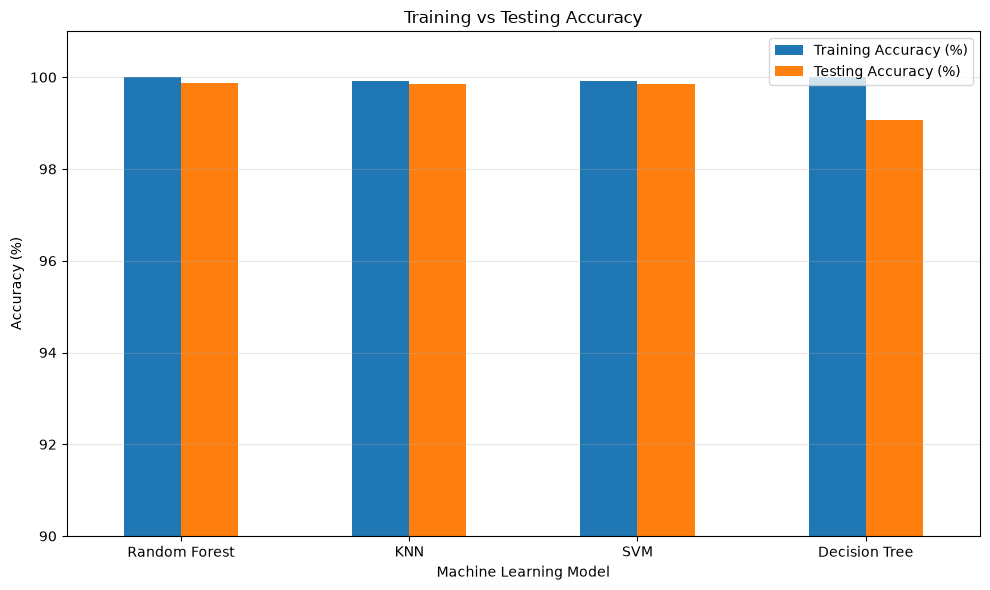

In [6]:
accuracy_plot = accuracy_results_df.set_index("Model")[
    ["Training Accuracy (%)", "Testing Accuracy (%)"]
]

accuracy_plot.plot(kind="bar", figsize=(10, 6))
plt.title("Training vs Testing Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.ylim(90, 101)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


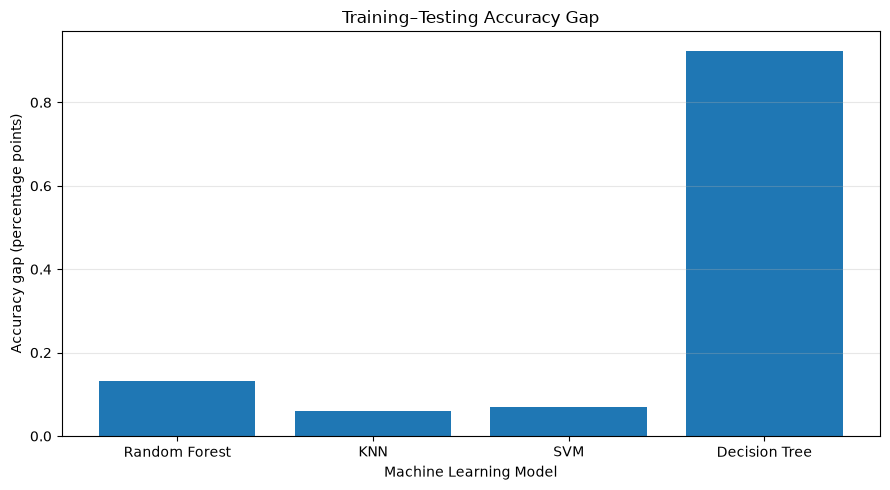

In [7]:
plt.figure(figsize=(9, 5))
plt.bar(
    accuracy_results_df["Model"],
    accuracy_results_df["Accuracy Gap (%)"]
)
plt.title("Training–Testing Accuracy Gap")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy gap (percentage points)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
accuracy_csv_path = RESULTS_DIR / "model_accuracy_comparison.csv"
accuracy_results_df.to_csv(accuracy_csv_path, index=False)

print("Saved:", accuracy_csv_path.resolve())


Saved: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\results\model_accuracy_comparison.csv


In [9]:
# Combine feature rows and assign a unique ID to each distinct row.
combined_features = np.concatenate(
    (eval_X_train, eval_X_test),
    axis=0
)

unique_features, inverse_ids = np.unique(
    combined_features,
    axis=0,
    return_inverse=True
)

train_group_ids = inverse_ids[:len(eval_X_train)]
test_group_ids = inverse_ids[len(eval_X_train):]

train_unique_groups = np.unique(train_group_ids)
test_unique_groups = np.unique(test_group_ids)

shared_groups = np.intersect1d(
    train_unique_groups,
    test_unique_groups,
    assume_unique=True
)

# Count testing rows whose exact feature vector occurs in training.
test_overlap_mask = np.isin(test_group_ids, shared_groups)
exact_overlap_count = int(test_overlap_mask.sum())

print("=" * 60)
print("EXACT DUPLICATE INVESTIGATION")
print("=" * 60)
print("Training samples:", len(eval_X_train))
print("Testing samples:", len(eval_X_test))
print("Unique feature vectors across both sets:", len(unique_features))
print("Shared exact feature groups:", len(shared_groups))
print("Testing samples with an exact training match:", exact_overlap_count)
print(
    "Percentage of test samples with exact matches:",
    round(exact_overlap_count / len(eval_X_test) * 100, 4),
    "%"
)


EXACT DUPLICATE INVESTIGATION
Training samples: 51500
Testing samples: 12876
Unique feature vectors across both sets: 63719
Shared exact feature groups: 192
Testing samples with an exact training match: 192
Percentage of test samples with exact matches: 1.4911 %


In [10]:
conflicting_shared_groups = []
consistent_shared_groups = []

for group_id in shared_groups:
    train_labels_for_group = np.unique(
        eval_y_train[train_group_ids == group_id]
    )
    test_labels_for_group = np.unique(
        eval_y_test[test_group_ids == group_id]
    )

    all_labels_for_group = np.unique(
        np.concatenate((train_labels_for_group, test_labels_for_group))
    )

    if len(all_labels_for_group) > 1:
        conflicting_shared_groups.append(group_id)
    else:
        consistent_shared_groups.append(group_id)

print("Shared exact groups with consistent labels:",
      len(consistent_shared_groups))
print("Shared exact groups with conflicting labels:",
      len(conflicting_shared_groups))


Shared exact groups with consistent labels: 192
Shared exact groups with conflicting labels: 0


In [11]:
match_examples = []

for group_id in shared_groups[:20]:
    train_indices = np.flatnonzero(train_group_ids == group_id)
    test_indices = np.flatnonzero(test_group_ids == group_id)

    match_examples.append({
        "Feature group ID": int(group_id),
        "Training occurrences": len(train_indices),
        "Testing occurrences": len(test_indices),
        "Training labels": np.unique(eval_y_train[train_indices]).tolist(),
        "Testing labels": np.unique(eval_y_test[test_indices]).tolist()
    })

exact_match_examples_df = pd.DataFrame(match_examples)
display(exact_match_examples_df)


,Feature group ID,Training occurrences,Testing occurrences,Training labels,Testing labels
0,29030,1,1,[T],[T]
1,29935,1,1,[T],[T]
2,30190,1,1,[T],[T]
3,30218,1,1,[T],[T]
4,30260,1,1,[T],[T]
5,30354,1,1,[T],[T]
6,30445,1,1,[T],[T]
7,30455,1,1,[T],[T]
8,30738,1,1,[T],[T]
9,30976,1,1,[T],[T]


In [12]:
exact_overlap_summary = pd.DataFrame([{
    "Training samples": len(eval_X_train),
    "Testing samples": len(eval_X_test),
    "Unique feature vectors": len(unique_features),
    "Shared exact feature groups": len(shared_groups),
    "Testing samples with exact training matches": exact_overlap_count,
    "Test overlap percentage": exact_overlap_count / len(eval_X_test) * 100,
    "Shared groups with conflicting labels": len(conflicting_shared_groups)
}])

exact_overlap_path = RESULTS_DIR / "exact_duplicate_investigation.csv"
exact_overlap_summary.to_csv(exact_overlap_path, index=False)

print("Saved:", exact_overlap_path.resolve())
display(exact_overlap_summary.round(4))


Saved: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\results\exact_duplicate_investigation.csv


,Training samples,Testing samples,Unique feature vectors,Shared exact feature groups,Testing samples with exact training matches,Test overlap percentage,Shared groups with conflicting labels
0,51500,12876,63719,192,192,1.4911,0


In [13]:
from sklearn.neighbors import NearestNeighbors

# Set a reproducible sample size. Increase gradually if runtime allows.
NEAR_DUP_TEST_SAMPLE_SIZE = min(2000, len(eval_X_test))
NEAR_DUP_RANDOM_STATE = 42

rng = np.random.default_rng(NEAR_DUP_RANDOM_STATE)
sampled_test_indices = rng.choice(
    len(eval_X_test),
    size=NEAR_DUP_TEST_SAMPLE_SIZE,
    replace=False
)

sampled_test_features = eval_X_test[sampled_test_indices]

# Fit nearest-neighbor search on training data.
nearest_model = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1
)
nearest_model.fit(eval_X_train)

nearest_distances, nearest_train_indices = nearest_model.kneighbors(
    sampled_test_features
)

nearest_distances = nearest_distances.ravel()
nearest_train_indices = nearest_train_indices.ravel()

print("Test samples checked:", len(sampled_test_indices))
print("Minimum nearest-training distance:", nearest_distances.min())
print("Median nearest-training distance:", np.median(nearest_distances))
print("Maximum nearest-training distance:", nearest_distances.max())


Test samples checked: 2000
Minimum nearest-training distance: 0.0
Median nearest-training distance: 0.19682224581832472
Maximum nearest-training distance: 5.589620357893546


In [14]:
exploratory_thresholds = [0.01, 0.05, 0.1, 0.2]

near_duplicate_rows = []

for threshold in exploratory_thresholds:
    count = int(np.sum(nearest_distances <= threshold))

    near_duplicate_rows.append({
        "Euclidean distance threshold": threshold,
        "Sampled test points within threshold": count,
        "Percentage of sampled test points": count / len(nearest_distances) * 100
    })

near_duplicate_summary = pd.DataFrame(near_duplicate_rows)
display(near_duplicate_summary.round(4))


,Euclidean distance threshold,Sampled test points within threshold,Percentage of sampled test points
0,0.01,30,1.50
1,0.05,138,6.90
2,0.10,463,23.15
3,0.20,1012,50.60


In [15]:
nearest_match_inspection = pd.DataFrame({
    "Test sample index": sampled_test_indices,
    "Test true label": eval_y_test[sampled_test_indices],
    "Nearest training sample index": nearest_train_indices,
    "Nearest training label": eval_y_train[nearest_train_indices],
    "Euclidean distance": nearest_distances
})

nearest_match_inspection = nearest_match_inspection.sort_values(
    "Euclidean distance"
).reset_index(drop=True)

display(nearest_match_inspection.head(30))


,Test sample index,Test true label,Nearest training sample index,Nearest training label,Euclidean distance
0,11263,T,23921,T,0.000000e+00
1,1776,T,7962,T,0.000000e+00
2,12847,Speak,36660,Speak,0.000000e+00
3,4325,Speak,12551,Speak,0.000000e+00
4,3567,Speak,51042,Speak,0.000000e+00
5,12073,Speak,42988,Speak,0.000000e+00
6,10519,T,9273,T,0.000000e+00
7,11496,T,40633,T,0.000000e+00
8,2791,Speak,32010,Speak,0.000000e+00
9,6253,T,38120,T,0.000000e+00


In [16]:
near_duplicate_path = RESULTS_DIR / "near_duplicate_screening.csv"
near_duplicate_summary.to_csv(near_duplicate_path, index=False)

nearest_match_path = RESULTS_DIR / "nearest_training_matches_sample.csv"
nearest_match_inspection.to_csv(nearest_match_path, index=False)

print("Saved:", near_duplicate_path.resolve())
print("Saved:", nearest_match_path.resolve())


Saved: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\results\near_duplicate_screening.csv
Saved: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\results\nearest_training_matches_sample.csv


In [17]:
required_variables = [
    "X",
    "y",
    "source_files",
    "timestamps",
    "metadata_df",
    "consecutive_distances_df"
]

for variable in required_variables:
    print(
        variable,
        "AVAILABLE" if variable in globals() else "NOT AVAILABLE"
    )

X NOT AVAILABLE
y NOT AVAILABLE
source_files NOT AVAILABLE
timestamps NOT AVAILABLE
metadata_df NOT AVAILABLE
consecutive_distances_df NOT AVAILABLE


In [18]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nProject root:")
print(PROJECT_ROOT.resolve())

print("\nDataset directory contents:")

dataset_folder = PROJECT_ROOT / "dataset"

if dataset_folder.exists():
    for item in dataset_folder.iterdir():
        print(item.name, "(folder)" if item.is_dir() else "(file)")
else:
    print("Dataset folder not found")

Current working directory:
C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\notebooks

Project root:
C:\Users\ASUS\Desktop\AMINDRA\American Sign Language

Dataset directory contents:
processed (folder)
raw (folder)


In [19]:
RAW_DIR = PROJECT_ROOT / "dataset" / "raw"

print("Raw dataset path:", RAW_DIR.resolve())
print("Raw dataset exists:", RAW_DIR.exists())

class_folders = [
    folder for folder in RAW_DIR.iterdir()
    if folder.is_dir()
]

print("Number of class folders:", len(class_folders))

for folder in sorted(class_folders):
    csv_files = list(folder.glob("*.csv"))
    print(f"{folder.name}: {len(csv_files)} CSV files")

Raw dataset path: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\dataset\raw
Raw dataset exists: True
Number of class folders: 0


In [20]:
print("Processed files:")

for file in sorted(PROCESSED_DIR.glob("*")):
    print(file.name)

Processed files:
standard_scaler.pkl
X_test_original.npy
X_test_scaled.npy
X_train_original.npy
X_train_scaled.npy
y_test.npy
y_train.npy


In [21]:
print("RAW DIRECTORY CONTENTS")
print("-" * 50)

for item in RAW_DIR.iterdir():
    print(
        item.name,
        "|",
        "FOLDER" if item.is_dir() else "FILE"
    )

RAW DIRECTORY CONTENTS
--------------------------------------------------


In [22]:
all_csv_files = list(RAW_DIR.rglob("*.csv"))

print("Total CSV files found:", len(all_csv_files))

print("\nFirst 20 CSV paths:")

for file in all_csv_files[:20]:
    print(file.relative_to(RAW_DIR))

Total CSV files found: 0

First 20 CSV paths:


In [23]:
for filename in [
    "X_train_original.npy",
    "X_test_original.npy",
    "y_train.npy",
    "y_test.npy"
]:
    path = PROCESSED_DIR / filename
    print(filename, "Exists:", path.exists())

X_train_original.npy Exists: True
X_test_original.npy Exists: True
y_train.npy Exists: True
y_test.npy Exists: True


In [24]:
dataset_path = Path("../media_pipe_keypoints_dataset")

In [25]:
dataset_path = PROJECT_ROOT / "media_pipe_keypoints_dataset"

print("Original dataset path:")
print(dataset_path.resolve())

print("\nDataset exists:", dataset_path.exists())

if dataset_path.exists():

    class_folders = [
        folder for folder in dataset_path.iterdir()
        if folder.is_dir()
    ]

    print("Number of class folders:", len(class_folders))

    total_files = 0

    for folder in sorted(class_folders):
        csv_files = list(folder.glob("*.csv"))
        print(folder.name, ":", len(csv_files))
        total_files += len(csv_files)

    print("\nTotal CSV files:", total_files)

Original dataset path:
C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\media_pipe_keypoints_dataset

Dataset exists: True
Number of class folders: 28
A : 2672
B : 2710
C : 2234
Confirm : 2786
D : 2549
E : 2499
F : 2673
G : 2359
H : 2928
I : 2329
J : 2617
K : 1926
L : 2149
M : 2232
N : 2544
O : 2507
P : 1855
Q : 1175
R : 2289
S : 2258
Space : 1114
Speak : 1742
T : 3909
U : 2608
V : 2698
W : 2368
X : 1477
Y : 1169

Total CSV files: 64376


In [26]:
import numpy as np
import pandas as pd
import re
from pathlib import Path

X = []
y = []
source_files = []

for class_folder in dataset_path.iterdir():

    if class_folder.is_dir():

        class_name = class_folder.name

        for csv_file in class_folder.glob("*.csv"):

            sample_data = pd.read_csv(csv_file)

            coordinates = sample_data[["X", "Y", "Z"]].to_numpy()

            flattened_sample = coordinates.flatten()

            X.append(flattened_sample)
            y.append(class_name)
            source_files.append(str(csv_file))

X = np.asarray(X)
y = np.asarray(y)
source_files = np.asarray(source_files)

print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Source files:", len(source_files))

Feature matrix: (64376, 63)
Labels: (64376,)
Source files: 64376


In [27]:
timestamps = []

for file_path in source_files:

    filename = Path(file_path).stem

    match = re.search(r"_(\d{13})$", filename)

    if match:
        timestamps.append(int(match.group(1)))
    else:
        timestamps.append(None)

timestamps = np.asarray(timestamps, dtype=object)

print("Total timestamps:", len(timestamps))
print("Valid timestamps:", sum(t is not None for t in timestamps))
print("Missing timestamps:", sum(t is None for t in timestamps))

Total timestamps: 64376
Valid timestamps: 29282
Missing timestamps: 35094


In [28]:
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(y))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_original = np.load(PROCESSED_DIR / "X_train_original.npy")
X_test_original = np.load(PROCESSED_DIR / "X_test_original.npy")

print(
    "Training features match:",
    np.array_equal(X[train_indices], X_train_original)
)

print(
    "Testing features match:",
    np.array_equal(X[test_indices], X_test_original)
)

Training features match: True
Testing features match: True


In [29]:
metadata_df = pd.DataFrame({
    "sample_index": np.arange(len(X)),
    "label": y,
    "source_file": source_files,
    "timestamp": timestamps
})

metadata_df["filename"] = metadata_df["source_file"].apply(
    lambda path: Path(path).name
)

print("Metadata shape:", metadata_df.shape)
print("Valid timestamps:", metadata_df["timestamp"].notna().sum())

display(metadata_df.head())

Metadata shape: (64376, 5)
Valid timestamps: 29282


,sample_index,label,source_file,timestamp,filename
0,0,A,..\media_pipe_keypoints_dataset\A\A_1.csv,None,A_1.csv
1,1,A,..\media_pipe_keypoints_dataset\A\A_10.csv,None,A_10.csv
2,2,A,..\media_pipe_keypoints_dataset\A\A_100.csv,None,A_100.csv
3,3,A,..\media_pipe_keypoints_dataset\A\A_1000.csv,None,A_1000.csv
4,4,A,..\media_pipe_keypoints_dataset\A\A_1001.csv,None,A_1001.csv


In [30]:
from scipy.spatial.distance import euclidean

consecutive_df = metadata_df[
    metadata_df["timestamp"].notna()
].copy()

consecutive_df["timestamp"] = pd.to_numeric(
    consecutive_df["timestamp"]
)

consecutive_df = consecutive_df.sort_values(
    ["label", "timestamp"]
)

consecutive_results = []

for class_name, class_data in consecutive_df.groupby("label"):

    class_data = class_data.sort_values("timestamp")

    sample_indices = class_data["sample_index"].to_numpy()
    sample_timestamps = class_data["timestamp"].to_numpy()

    for i in range(len(class_data) - 1):

        first_index = sample_indices[i]
        second_index = sample_indices[i + 1]

        time_gap = (
            sample_timestamps[i + 1] - sample_timestamps[i]
        ) / 1000

        distance = euclidean(
            X[first_index],
            X[second_index]
        )

        consecutive_results.append({
            "label": class_name,
            "first_sample_index": first_index,
            "second_sample_index": second_index,
            "time_gap_seconds": time_gap,
            "euclidean_distance": distance
        })

consecutive_distances_df = pd.DataFrame(consecutive_results)

print("Total consecutive pairs:", len(consecutive_distances_df))

Total consecutive pairs: 29258


In [31]:
section22_close_pairs = consecutive_distances_df[
    (consecutive_distances_df["time_gap_seconds"] > 0) &
    (consecutive_distances_df["time_gap_seconds"] <= 1)
].copy()

print(
    "Consecutive pairs within 1 second:",
    len(section22_close_pairs)
)

display(section22_close_pairs.head())

Consecutive pairs within 1 second: 29224


,label,first_sample_index,second_sample_index,time_gap_seconds,euclidean_distance
0,A,341,342,0.343,0.041646
1,A,342,343,0.326,0.042511
2,A,343,344,0.339,0.033139
3,A,344,345,0.331,0.066899
4,A,345,346,0.334,0.026457


In [32]:
rng = np.random.default_rng(42)

section22_random_distances = []

for class_name in np.unique(y):

    class_indices = np.where(y == class_name)[0]

    number_of_pairs = min(1000, len(class_indices) // 2)

    for _ in range(number_of_pairs):

        first_index, second_index = rng.choice(
            class_indices,
            size=2,
            replace=False
        )

        distance = np.linalg.norm(
            X[first_index] - X[second_index]
        )

        section22_random_distances.append({
            "label": class_name,
            "first_sample_index": first_index,
            "second_sample_index": second_index,
            "euclidean_distance": distance
        })

section22_random_pairs_df = pd.DataFrame(
    section22_random_distances
)

print(
    "Random same-class pairs:",
    len(section22_random_pairs_df)
)

display(section22_random_pairs_df.head())

Random same-class pairs: 26227


,label,first_sample_index,second_sample_index,euclidean_distance
0,A,238,2068,1.666704
1,A,1172,1157,0.114883
2,A,1863,229,0.943051
3,A,251,1406,0.366824
4,A,1965,2033,0.232359


In [33]:
section22_comparison = pd.DataFrame({
    "Consecutive samples":
        section22_close_pairs["euclidean_distance"].describe(),

    "Random same-class samples":
        section22_random_pairs_df["euclidean_distance"].describe()
})

display(section22_comparison)

,Consecutive samples,Random same-class samples
count,29224.000000,26227.000000
mean,0.041585,0.815162
std,0.106303,0.632589
min,0.002748,0.000000
25%,0.014592,0.186637
50%,0.022439,0.799432
75%,0.038504,1.279495
max,2.667351,4.256915


In [34]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

section22_comparison.to_csv(
    RESULTS_DIR / "section22_similarity_comparison.csv"
    if "RESULTS_DIR" in globals()
    else PROJECT_ROOT / "results" / "section22_similarity_comparison.csv"
)

section22_close_pairs.to_csv(
    PROJECT_ROOT / "results" / "section22_consecutive_pairs.csv",
    index=False
)

section22_random_pairs_df.to_csv(
    PROJECT_ROOT / "results" / "section22_random_pairs.csv",
    index=False
)

print("Section 22 results saved successfully.")

Section 22 results saved successfully.


In [35]:
section23_class_stats = (
    section22_close_pairs
    .groupby("label")["euclidean_distance"]
    .agg(
        sample_pairs="count",
        mean_distance="mean",
        median_distance="median",
        std_distance="std",
        min_distance="min",
        max_distance="max"
    )
    .reset_index()
)

section23_class_stats = section23_class_stats.sort_values(
    "median_distance"
)

display(section23_class_stats)

,label,sample_pairs,mean_distance,median_distance,std_distance,min_distance,max_distance
6,F,1478,0.018295,0.012508,0.023099,0.002912,0.377656
1,B,1211,0.020691,0.014914,0.020474,0.003475,0.244262
20,T,2010,0.032902,0.015737,0.118528,0.002879,2.663188
4,D,1479,0.027643,0.017032,0.068116,0.003692,1.743219
9,I,1049,0.027880,0.017525,0.027843,0.004201,0.208017
17,R,1197,0.029662,0.019317,0.108381,0.005422,2.548110
13,M,1092,0.031424,0.019401,0.153064,0.005947,2.667351
10,J,1329,0.027226,0.019995,0.024881,0.005234,0.261108
14,N,1173,0.044041,0.020755,0.189610,0.006622,2.465076
0,A,1414,0.027390,0.020795,0.024066,0.004933,0.240787


In [36]:
most_similar_class = section23_class_stats.iloc[0]
least_similar_class = section23_class_stats.iloc[-1]

print("Strongest temporal similarity:")
print(most_similar_class)

print("\nWeakest temporal similarity:")
print(least_similar_class)

Strongest temporal similarity:
label                     F
sample_pairs           1478
mean_distance      0.018295
median_distance    0.012508
std_distance       0.023099
min_distance       0.002912
max_distance       0.377656
Name: 6, dtype: object

Weakest temporal similarity:
label                     P
sample_pairs            716
mean_distance      0.088488
median_distance    0.048711
std_distance       0.165506
min_distance       0.010817
max_distance       1.838258
Name: 16, dtype: object


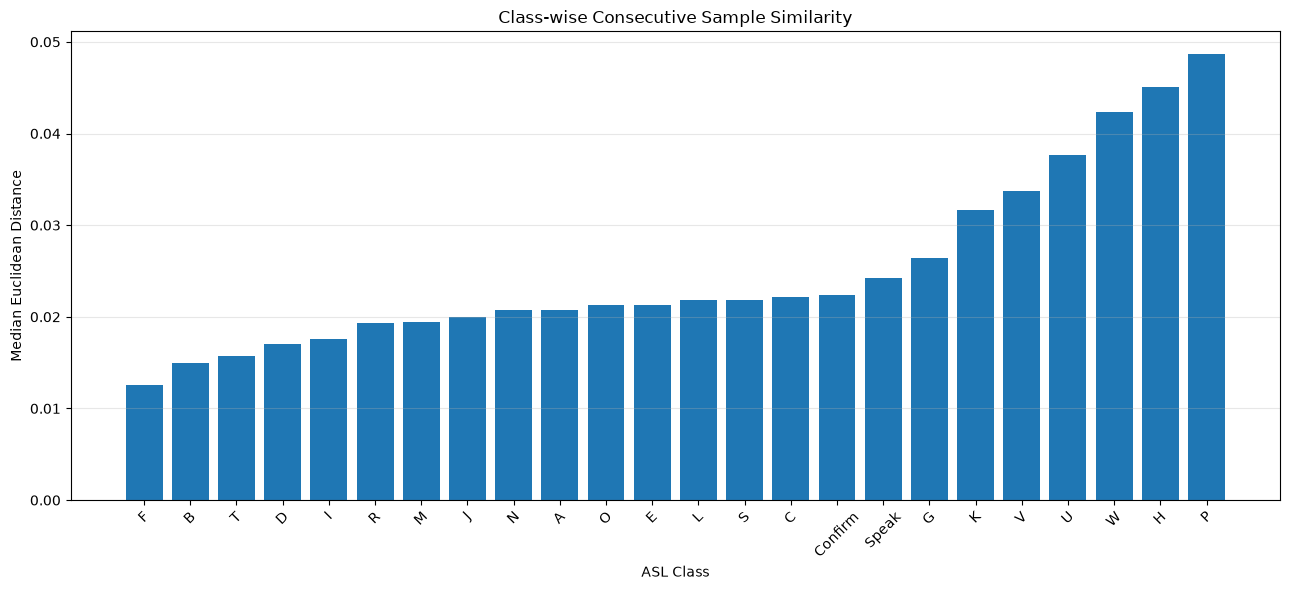

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 6))

plt.bar(
    section23_class_stats["label"],
    section23_class_stats["median_distance"]
)

plt.xlabel("ASL Class")
plt.ylabel("Median Euclidean Distance")
plt.title("Class-wise Consecutive Sample Similarity")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
section23_class_stats.to_csv(
    PROJECT_ROOT / "results" / "section23_classwise_similarity.csv",
    index=False
)

print("Section 23 results saved successfully.")

Section 23 results saved successfully.


In [39]:
section24_consecutive_stats = (
    section22_close_pairs
    .groupby("label")["euclidean_distance"]
    .agg(
        consecutive_pairs="count",
        consecutive_mean="mean",
        consecutive_median="median"
    )
    .reset_index()
)

display(section24_consecutive_stats)

,label,consecutive_pairs,consecutive_mean,consecutive_median
0,A,1414,0.027390,0.020795
1,B,1211,0.020691,0.014914
2,C,549,0.029054,0.022113
3,Confirm,2774,0.043994,0.022430
4,D,1479,0.027643,0.017032
5,E,1247,0.033501,0.021292
6,F,1478,0.018295,0.012508
7,G,1173,0.038504,0.026468
8,H,1551,0.069147,0.045054
9,I,1049,0.027880,0.017525


In [40]:
section24_random_stats = (
    section22_random_pairs_df
    .groupby("label")["euclidean_distance"]
    .agg(
        random_pairs="count",
        random_mean="mean",
        random_median="median"
    )
    .reset_index()
)

display(section24_random_stats)

,label,random_pairs,random_mean,random_median
0,A,1000,1.001616,0.829385
1,B,1000,0.721267,0.697169
2,C,1000,0.701281,0.665491
3,Confirm,1000,0.629101,0.661534
4,D,1000,0.978847,1.113135
5,E,1000,0.828823,1.018719
6,F,1000,0.796968,0.830262
7,G,1000,0.902082,1.274954
8,H,1000,0.928920,0.975589
9,I,1000,0.886436,0.999111


In [41]:
section24_comparison = pd.merge(
    section24_consecutive_stats,
    section24_random_stats,
    on="label",
    how="inner"
)

section24_comparison["median_distance_ratio"] = (
    section24_comparison["random_median"] /
    section24_comparison["consecutive_median"]
)

section24_comparison = section24_comparison.sort_values(
    "median_distance_ratio",
    ascending=False
)

display(section24_comparison)

,label,consecutive_pairs,consecutive_mean,consecutive_median,random_pairs,random_mean,random_median,median_distance_ratio
6,F,1478,0.018295,0.012508,1000,0.796968,0.830262,66.376194
4,D,1479,0.027643,0.017032,1000,0.978847,1.113135,65.356719
17,R,1197,0.029662,0.019317,1000,0.906537,1.230572,63.704878
20,T,2010,0.032902,0.015737,1000,0.926701,0.943734,59.970280
9,I,1049,0.027880,0.017525,1000,0.886436,0.999111,57.010898
12,L,1003,0.039688,0.021870,1000,0.938549,1.174729,53.713152
18,S,1146,0.033744,0.021876,1000,0.730211,1.073951,49.092644
7,G,1173,0.038504,0.026468,1000,0.902082,1.274954,48.170283
5,E,1247,0.033501,0.021292,1000,0.828823,1.018719,47.845216
13,M,1092,0.031424,0.019401,1000,0.702062,0.914161,47.118243


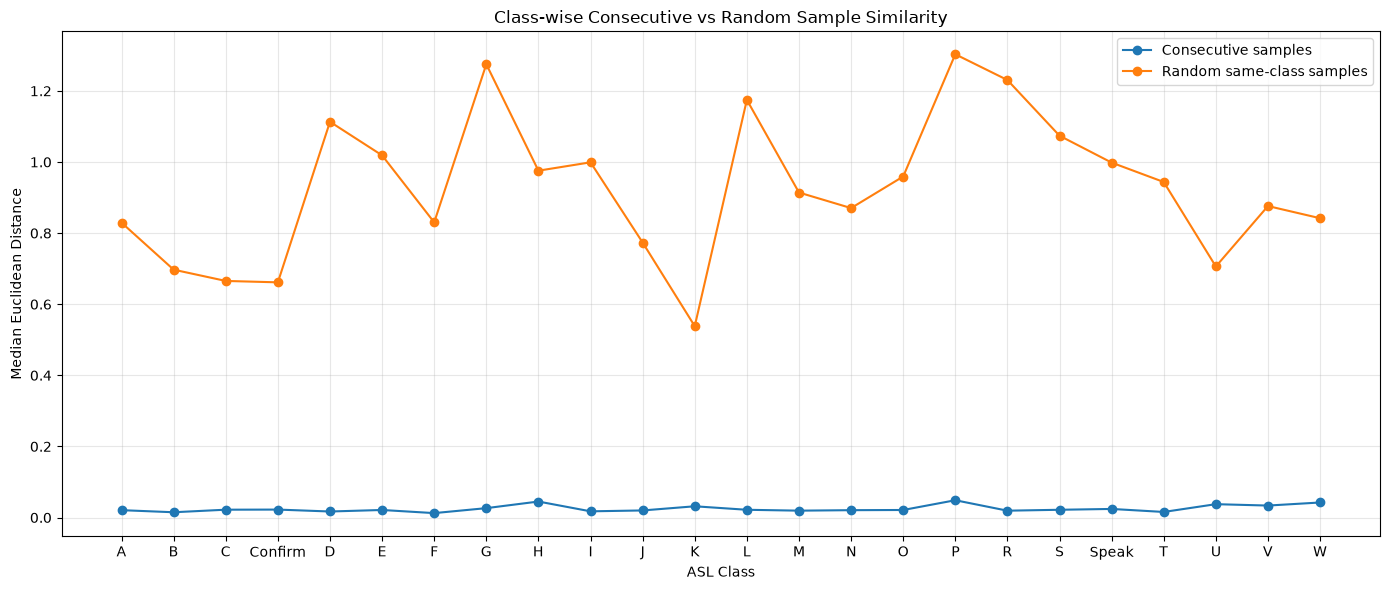

In [42]:
import matplotlib.pyplot as plt

plot_df = section24_comparison.sort_values("label")

plt.figure(figsize=(14, 6))

plt.plot(
    plot_df["label"],
    plot_df["consecutive_median"],
    marker="o",
    label="Consecutive samples"
)

plt.plot(
    plot_df["label"],
    plot_df["random_median"],
    marker="o",
    label="Random same-class samples"
)

plt.xlabel("ASL Class")
plt.ylabel("Median Euclidean Distance")
plt.title("Class-wise Consecutive vs Random Sample Similarity")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
section24_comparison.to_csv(
    PROJECT_ROOT / "results" / "section24_classwise_comparison.csv",
    index=False
)

print("Section 24 results saved successfully.")

Section 24 results saved successfully.


In [44]:
section25_df = consecutive_df.copy()

section25_df = section25_df.sort_values(
    ["label", "timestamp"]
)

section25_df["time_gap_seconds"] = (
    section25_df.groupby("label")["timestamp"]
    .diff() / 1000
)

section25_gaps = section25_df[
    section25_df["time_gap_seconds"].notna() &
    (section25_df["time_gap_seconds"] > 0)
].copy()

print("Total timestamp gaps:", len(section25_gaps))

display(section25_gaps.head())

Total timestamp gaps: 29258


,sample_index,label,source_file,timestamp,filename,time_gap_seconds
342,342,A,..\media_pipe_keypoints_dataset\A\A_1742812468...,1742812468641,A_1742812468641.csv,0.343
343,343,A,..\media_pipe_keypoints_dataset\A\A_1742812468...,1742812468967,A_1742812468967.csv,0.326
344,344,A,..\media_pipe_keypoints_dataset\A\A_1742812469...,1742812469306,A_1742812469306.csv,0.339
345,345,A,..\media_pipe_keypoints_dataset\A\A_1742812469...,1742812469637,A_1742812469637.csv,0.331
346,346,A,..\media_pipe_keypoints_dataset\A\A_1742812469...,1742812469971,A_1742812469971.csv,0.334


In [45]:
section25_gaps["time_gap_seconds"].describe()

count    2.925800e+04
mean     3.667180e+02
std      3.127104e+04
min      3.000000e-01
25%      3.300000e-01
50%      3.330000e-01
75%      3.360000e-01
max      2.689897e+06
Name: time_gap_seconds, dtype: float64

In [46]:
thresholds = [1, 5, 10, 30, 60, 300]

section25_threshold_results = []

for threshold in thresholds:

    number_of_blocks = (
        section25_gaps["time_gap_seconds"] > threshold
    ).sum() + section25_gaps["label"].nunique()

    section25_threshold_results.append({
        "gap_threshold_seconds": threshold,
        "estimated_temporal_blocks": number_of_blocks
    })

section25_threshold_df = pd.DataFrame(
    section25_threshold_results
)

display(section25_threshold_df)

,gap_threshold_seconds,estimated_temporal_blocks
0,1,58
1,5,48
2,10,47
3,30,46
4,60,41
5,300,34


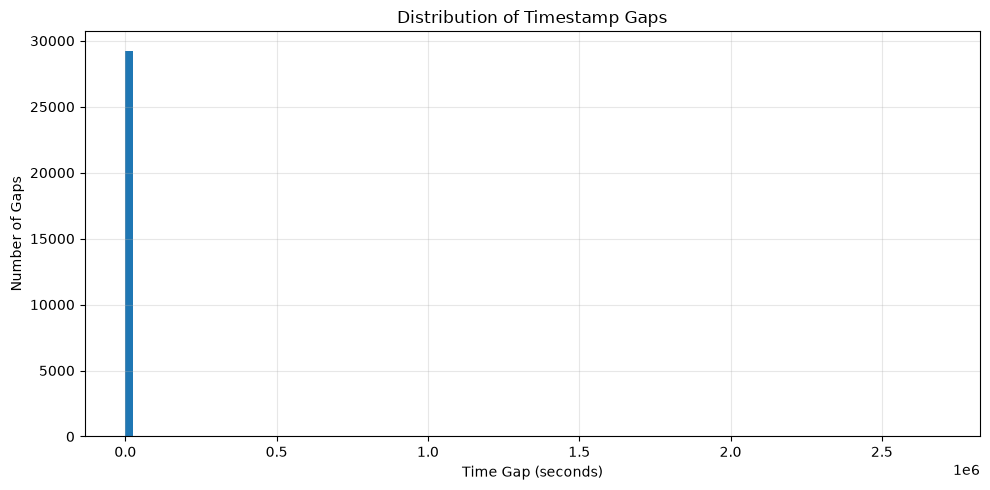

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    section25_gaps["time_gap_seconds"],
    bins=100
)

plt.xlabel("Time Gap (seconds)")
plt.ylabel("Number of Gaps")

plt.title("Distribution of Timestamp Gaps")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
section25_gaps.to_csv(
    PROJECT_ROOT / "results" / "section25_timestamp_gaps.csv",
    index=False
)

section25_threshold_df.to_csv(
    PROJECT_ROOT / "results" / "section25_threshold_analysis.csv",
    index=False
)

print("Section 25 results saved successfully.")

Section 25 results saved successfully.


In [49]:

# finding the 30 largest gaps

section26_largest_gaps = section25_gaps.sort_values(
    "time_gap_seconds",
    ascending=False
).head(30).copy()

display(
    section26_largest_gaps[
        [
            "label",
            "sample_index",
            "filename",
            "timestamp",
            "time_gap_seconds"
        ]
    ]
)

,label,sample_index,filename,timestamp,time_gap_seconds
43024,R,43024,R_1742839903491.csv,1742839903491,2689896.657
24096,I,24096,I_1742832129124.csv,1742832129124,2679603.941
13386,E,13386,E_1742815912769.csv,1742815912769,2666411.462
8932,Confirm,8932,Confirm_1742819159086.csv,1742819159086,2662326.309
8100,Confirm,8100,Confirm_1740154974191.csv,1740154974191,11457.683
51222,T,51222,T_1740157136505.csv,1740157136505,4006.858
23891,I,23891,I_1740152457172.csv,1740152457172,2613.670
8585,Confirm,8585,Confirm_1740156717377.csv,1740156717377,1581.733
1060,A,1060,A_1742813119829.csv,1742813119829,410.611
7618,Confirm,7618,Confirm_1740143184589.csv,1740143184589,314.335


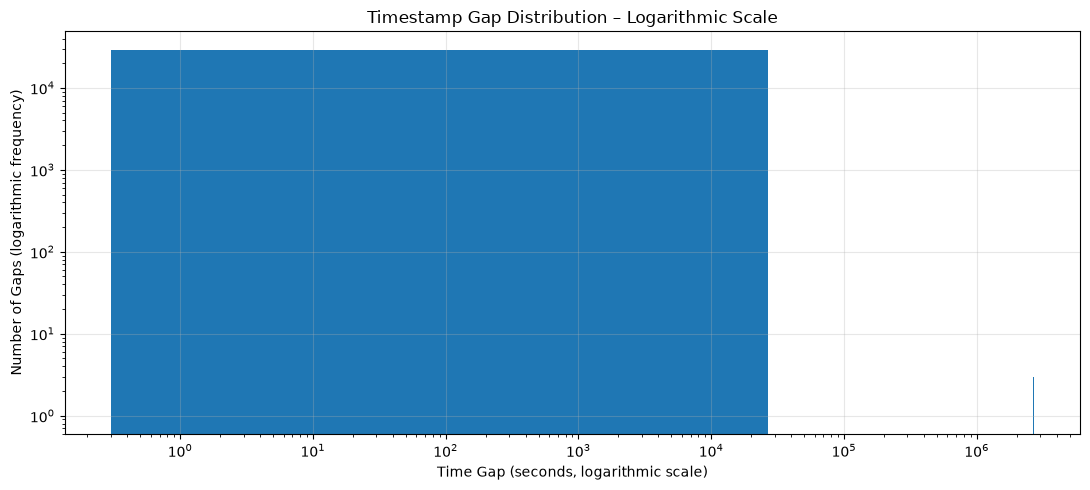

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.hist(
    section25_gaps["time_gap_seconds"],
    bins=100,
    log=True
)

plt.xscale("log")

plt.xlabel("Time Gap (seconds, logarithmic scale)")
plt.ylabel("Number of Gaps (logarithmic frequency)")
plt.title("Timestamp Gap Distribution – Logarithmic Scale")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
gap_thresholds = [1, 5, 10, 30, 60, 300, 3600, 86400]

section26_large_gap_counts = pd.DataFrame({
    "threshold_seconds": gap_thresholds,
    "number_of_gaps": [
        (section25_gaps["time_gap_seconds"] > threshold).sum()
        for threshold in gap_thresholds
    ]
})

display(section26_large_gap_counts)

,threshold_seconds,number_of_gaps
0,1,34
1,5,24
2,10,23
3,30,22
4,60,17
5,300,10
6,3600,6
7,86400,4


In [52]:
section26_largest_gaps.to_csv(
    PROJECT_ROOT / "results" / "section26_largest_gaps.csv",
    index=False
)

section26_large_gap_counts.to_csv(
    PROJECT_ROOT / "results" / "section26_large_gap_counts.csv",
    index=False
)

print("Section 26 results saved successfully.")

Section 26 results saved successfully.


In [53]:
section27_df = metadata_df[
    metadata_df["timestamp"].notna()
].copy()

section27_df["timestamp"] = pd.to_numeric(
    section27_df["timestamp"]
)

section27_df["datetime"] = pd.to_datetime(
    section27_df["timestamp"],
    unit="ms",
    utc=True
)

print("Earliest timestamp:")
print(section27_df["datetime"].min())

print("\nLatest timestamp:")
print(section27_df["datetime"].max())

display(section27_df.head())

Earliest timestamp:
2025-02-21 13:01:10.254000+00:00

Latest timestamp:
2025-03-24 18:55:45.875000+00:00


,sample_index,label,source_file,timestamp,filename,datetime
341,341,A,..\media_pipe_keypoints_dataset\A\A_1742812468...,1742812468298,A_1742812468298.csv,2025-03-24 10:34:28.298+00:00
342,342,A,..\media_pipe_keypoints_dataset\A\A_1742812468...,1742812468641,A_1742812468641.csv,2025-03-24 10:34:28.641+00:00
343,343,A,..\media_pipe_keypoints_dataset\A\A_1742812468...,1742812468967,A_1742812468967.csv,2025-03-24 10:34:28.967+00:00
344,344,A,..\media_pipe_keypoints_dataset\A\A_1742812469...,1742812469306,A_1742812469306.csv,2025-03-24 10:34:29.306+00:00
345,345,A,..\media_pipe_keypoints_dataset\A\A_1742812469...,1742812469637,A_1742812469637.csv,2025-03-24 10:34:29.637+00:00


In [54]:
section27_df["date"] = section27_df["datetime"].dt.date

daily_counts = (
    section27_df.groupby("date")
    .size()
    .reset_index(name="sample_count")
    .sort_values("date")
)

print("Number of distinct dates:", len(daily_counts))

display(daily_counts)

Number of distinct dates: 2


,date,sample_count
0,2025-02-21,4740
1,2025-03-24,24542


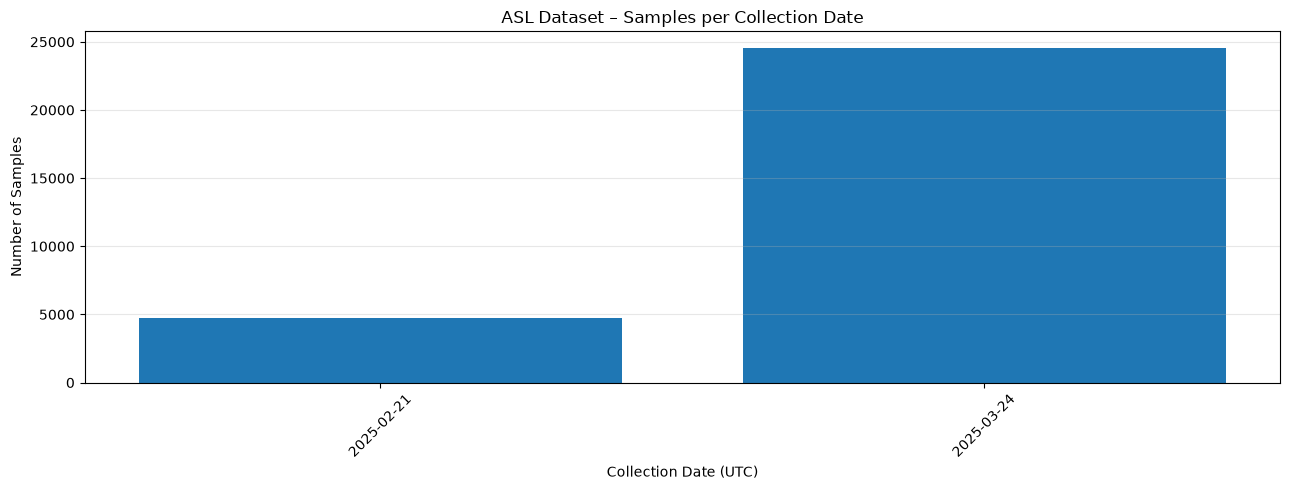

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.bar(
    daily_counts["date"].astype(str),
    daily_counts["sample_count"]
)

plt.xlabel("Collection Date (UTC)")
plt.ylabel("Number of Samples")
plt.title("ASL Dataset – Samples per Collection Date")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
daily_counts.to_csv(
    PROJECT_ROOT / "results" / "section27_daily_counts.csv",
    index=False
)

print("Section 27 results saved successfully.")

Section 27 results saved successfully.


In [57]:
import numpy as np
import pandas as pd

# Ensure arrays are contiguous
train_data = np.ascontiguousarray(X_train_original)
test_data = np.ascontiguousarray(X_test_original)

# Convert each feature vector into a comparable byte representation
train_rows = train_data.view(
    np.dtype((np.void, train_data.dtype.itemsize * train_data.shape[1]))
).ravel()

test_rows = test_data.view(
    np.dtype((np.void, test_data.dtype.itemsize * test_data.shape[1]))
).ravel()

# Find test samples that have an exact training match
duplicate_mask = np.isin(test_rows, np.unique(train_rows))

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print("Exact duplicate test samples:", duplicate_mask.sum())

print(
    "Duplicate percentage:",
    round(duplicate_mask.mean() * 100, 4),
    "%"
)

Training samples: 51500
Testing samples: 12876
Exact duplicate test samples: 192
Duplicate percentage: 1.4911 %


In [58]:
import numpy as np
import pandas as pd

# Ensure arrays are contiguous
train_data = np.ascontiguousarray(X_train_original)
test_data = np.ascontiguousarray(X_test_original)

# Convert each feature vector into a comparable byte representation
train_rows = train_data.view(
    np.dtype((np.void, train_data.dtype.itemsize * train_data.shape[1]))
).ravel()

test_rows = test_data.view(
    np.dtype((np.void, test_data.dtype.itemsize * test_data.shape[1]))
).ravel()

# Find test samples that have an exact training match
duplicate_mask = np.isin(test_rows, np.unique(train_rows))

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print("Exact duplicate test samples:", duplicate_mask.sum())

print(
    "Duplicate percentage:",
    round(duplicate_mask.mean() * 100, 4),
    "%"
)

Training samples: 51500
Testing samples: 12876
Exact duplicate test samples: 192
Duplicate percentage: 1.4911 %


In [59]:
y_train = np.load(PROCESSED_DIR / "y_train.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Training features:", X_train_original.shape)
print("Testing features:", X_test_original.shape)

Training labels: (51500,)
Testing labels: (12876,)
Training features: (51500, 63)
Testing features: (12876, 63)


In [60]:
# Create a lookup of training samples and their labels
train_label_lookup = {}

for i, label in enumerate(y_train):

    row_key = train_data[i].tobytes()

    train_label_lookup.setdefault(row_key, set()).add(label)


# Inspect exact duplicate test samples
duplicate_results = []

for i in np.where(duplicate_mask)[0]:

    row_key = test_data[i].tobytes()

    matching_labels = train_label_lookup[row_key]

    duplicate_results.append({
        "test_index": i,
        "test_label": y_test[i],
        "training_labels": list(matching_labels),
        "labels_match": (
            len(matching_labels) == 1 and
            y_test[i] in matching_labels
        )
    })


duplicate_df = pd.DataFrame(duplicate_results)

print("Duplicate records:", len(duplicate_df))

print(
    "Label-consistent duplicates:",
    duplicate_df["labels_match"].sum()
)

print(
    "Conflicting duplicates:",
    (~duplicate_df["labels_match"]).sum()
)

display(duplicate_df.head(10))

Duplicate records: 192
Label-consistent duplicates: 192
Conflicting duplicates: 0


,test_index,test_label,training_labels,labels_match
0,41,Speak,[Speak],True
1,184,Speak,[Speak],True
2,236,T,[T],True
3,292,T,[T],True
4,491,T,[T],True
5,591,T,[T],True
6,604,T,[T],True
7,660,T,[T],True
8,700,T,[T],True
9,750,Speak,[Speak],True


In [61]:
duplicate_df.to_csv(
    PROJECT_ROOT / "results" / "section29_exact_leakage_check.csv",
    index=False
)

print("Exact leakage investigation saved successfully.")

Exact leakage investigation saved successfully.


In [62]:
# Create a lookup of training samples and their labels
train_label_lookup = {}

for i, label in enumerate(y_train):

    row_key = train_data[i].tobytes()

    train_label_lookup.setdefault(row_key, set()).add(label)


# Inspect exact duplicate test samples
duplicate_results = []

for i in np.where(duplicate_mask)[0]:

    row_key = test_data[i].tobytes()

    matching_labels = train_label_lookup[row_key]

    duplicate_results.append({
        "test_index": i,
        "test_label": y_test[i],
        "training_labels": list(matching_labels),
        "labels_match": (
            len(matching_labels) == 1 and
            y_test[i] in matching_labels
        )
    })


duplicate_df = pd.DataFrame(duplicate_results)

print("Duplicate records:", len(duplicate_df))

print(
    "Label-consistent duplicates:",
    duplicate_df["labels_match"].sum()
)

print(
    "Conflicting duplicates:",
    (~duplicate_df["labels_match"]).sum()
)

display(duplicate_df.head(10))

Duplicate records: 192
Label-consistent duplicates: 192
Conflicting duplicates: 0


,test_index,test_label,training_labels,labels_match
0,41,Speak,[Speak],True
1,184,Speak,[Speak],True
2,236,T,[T],True
3,292,T,[T],True
4,491,T,[T],True
5,591,T,[T],True
6,604,T,[T],True
7,660,T,[T],True
8,700,T,[T],True
9,750,Speak,[Speak],True


In [63]:
from sklearn.ensemble import RandomForestClassifier

rf_models = {
    name: obj
    for name, obj in globals().copy().items()
    if isinstance(obj, RandomForestClassifier)
    and hasattr(obj, "estimators_")
}

print("Available trained Random Forest models:")

for name in rf_models:
    print(name)

Available trained Random Forest models:
model_instance


In [64]:
X_test_scaled = np.load(
    PROCESSED_DIR / "X_test_scaled.npy"
)

print("Test features:", X_test_scaled.shape)
print("Test labels:", y_test.shape)
print("Duplicate mask:", duplicate_mask.shape)

Test features: (12876, 63)
Test labels: (12876,)
Duplicate mask: (12876,)


In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Original model predictions
y_pred_full = model_instance.predict(X_test_scaled)

# Original test accuracy
original_accuracy = accuracy_score(
    y_test,
    y_pred_full
)

print("Original Test Accuracy:",
      round(original_accuracy * 100, 4), "%")

Original Test Accuracy: 99.868 %


In [66]:
# Keep only test samples without exact training duplicates
clean_mask = ~duplicate_mask

X_test_clean = X_test_scaled[clean_mask]
y_test_clean = y_test[clean_mask]

# Corresponding predictions from the original model
y_pred_clean = y_pred_full[clean_mask]

print("Original test samples:", len(y_test))
print("Duplicate samples removed:", duplicate_mask.sum())
print("Remaining test samples:", len(y_test_clean))

Original test samples: 12876
Duplicate samples removed: 192
Remaining test samples: 12684


In [67]:
clean_accuracy = accuracy_score(
    y_test_clean,
    y_pred_clean
)

clean_precision = precision_score(
    y_test_clean,
    y_pred_clean,
    average="weighted",
    zero_division=0
)

clean_recall = recall_score(
    y_test_clean,
    y_pred_clean,
    average="weighted",
    zero_division=0
)

clean_f1 = f1_score(
    y_test_clean,
    y_pred_clean,
    average="weighted",
    zero_division=0
)

print("Clean Test Accuracy:",
      round(clean_accuracy * 100, 4), "%")

print("Clean Precision:",
      round(clean_precision, 4))

print("Clean Recall:",
      round(clean_recall, 4))

print("Clean F1-score:",
      round(clean_f1, 4))

Clean Test Accuracy: 99.866 %
Clean Precision: 0.9987
Clean Recall: 0.9987
Clean F1-score: 0.9987


In [68]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Original Test": [
        accuracy_score(y_test, y_pred_full),
        precision_score(y_test, y_pred_full, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_full, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_full, average="weighted", zero_division=0)
    ],
    "After Removing Exact Duplicates": [
        clean_accuracy,
        clean_precision,
        clean_recall,
        clean_f1
    ]
})

display(comparison)

print(
    "Accuracy difference (percentage points):",
    round((original_accuracy - clean_accuracy) * 100, 4)
)

,Metric,Original Test,After Removing Exact Duplicates
0,Accuracy,0.998680,0.998660
1,Precision,0.998682,0.998662
2,Recall,0.998680,0.998660
3,F1-score,0.998679,0.998659


Accuracy difference (percentage points): 0.002


In [69]:
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(y_train) + len(y_test))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42,
    stratify=np.concatenate([y_train, y_test])
)

In [70]:
# Reconstruct original complete labels
y = np.concatenate([y_train, y_test])

# Verify that the original indices match the saved feature arrays
print("Training and testing sizes:", len(train_indices), len(test_indices))

Training and testing sizes: 51500 12876


In [71]:
for name in [
    "train_indices",
    "test_indices",
    "consecutive_distances_df",
    "split_lookup",
    "cross_split_pairs"
]:
    print(name, ":", name in globals())

train_indices : True
test_indices : True
consecutive_distances_df : True
split_lookup : False
cross_split_pairs : False


In [72]:
# Restore labels in their original dataset order
y_full = (
    metadata_df
    .sort_values("sample_index")["label"]
    .to_numpy()
)

print("Full labels:", y_full.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Full labels: (64376,)
Training labels: (51500,)
Testing labels: (12876,)


In [73]:
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(y_full))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

# Verify against the saved original data
print(
    "Training labels match:",
    np.array_equal(y_full[train_indices], y_train)
)

print(
    "Testing labels match:",
    np.array_equal(y_full[test_indices], y_test)
)

print(
    "Training features match:",
    np.array_equal(X[train_indices], X_train_original)
)

print(
    "Testing features match:",
    np.array_equal(X[test_indices], X_test_original)
)

Training labels match: True
Testing labels match: True
Training features match: True
Testing features match: True


In [74]:
split_lookup = {}

for index in train_indices:
    split_lookup[int(index)] = "train"

for index in test_indices:
    split_lookup[int(index)] = "test"

consecutive_distances_df["first_split"] = (
    consecutive_distances_df["first_sample_index"]
    .map(split_lookup)
)

consecutive_distances_df["second_split"] = (
    consecutive_distances_df["second_sample_index"]
    .map(split_lookup)
)

close_pairs = consecutive_distances_df[
    (consecutive_distances_df["time_gap_seconds"] > 0) &
    (consecutive_distances_df["time_gap_seconds"] <= 1)
].copy()

cross_split_pairs = close_pairs[
    close_pairs["first_split"] != close_pairs["second_split"]
].copy()

print("Close-time pairs:", len(close_pairs))
print("Cross-split pairs:", len(cross_split_pairs))

Close-time pairs: 29224
Cross-split pairs: 9388


In [75]:
split_lookup = {}

for index in train_indices:
    split_lookup[int(index)] = "train"

for index in test_indices:
    split_lookup[int(index)] = "test"

print("Total mapped samples:", len(split_lookup))

Total mapped samples: 64376


In [76]:
consecutive_distances_df["first_split"] = (
    consecutive_distances_df["first_sample_index"]
    .map(split_lookup)
)

consecutive_distances_df["second_split"] = (
    consecutive_distances_df["second_sample_index"]
    .map(split_lookup)
)

close_pairs = consecutive_distances_df[
    (consecutive_distances_df["time_gap_seconds"] > 0) &
    (consecutive_distances_df["time_gap_seconds"] <= 1)
].copy()

cross_split_pairs = close_pairs[
    close_pairs["first_split"] != close_pairs["second_split"]
].copy()

print("Close-time pairs:", len(close_pairs))
print("Cross-split pairs:", len(cross_split_pairs))

print(
    "Cross-split percentage:",
    round(len(cross_split_pairs) / len(close_pairs) * 100, 2),
    "%"
)

display(cross_split_pairs.head(10))

Close-time pairs: 29224
Cross-split pairs: 9388
Cross-split percentage: 32.12 %


,label,first_sample_index,second_sample_index,time_gap_seconds,euclidean_distance,first_split,second_split
14,A,355,356,0.329,0.014237,train,test
15,A,356,357,0.343,0.027047,test,train
27,A,368,369,0.333,0.034631,train,test
28,A,369,370,0.332,0.183747,test,train
36,A,377,378,0.327,0.021611,train,test
38,A,379,380,0.334,0.048483,test,train
49,A,390,391,0.327,0.008858,train,test
51,A,392,393,0.336,0.025698,test,train
53,A,394,395,0.334,0.015335,train,test
56,A,397,398,0.348,0.014902,test,train


In [77]:
temporal_test_indices = set()

for _, row in cross_split_pairs.iterrows():

    if row["first_split"] == "test":
        temporal_test_indices.add(
            int(row["first_sample_index"])
        )

    if row["second_split"] == "test":
        temporal_test_indices.add(
            int(row["second_sample_index"])
        )

print(
    "Unique test samples with training neighbours:",
    len(temporal_test_indices)
)

print(
    "Percentage of test dataset:",
    round(
        len(temporal_test_indices) / len(y_test) * 100,
        2
    ),
    "%"
)

Unique test samples with training neighbours: 5629
Percentage of test dataset: 43.72 %


In [78]:
# Map original dataset indices to positions in the test array

test_position_lookup = {
    int(original_index): position
    for position, original_index in enumerate(test_indices)
}

# Convert affected original indices into test-array positions

temporal_test_positions = {
    test_position_lookup[index]
    for index in temporal_test_indices
    if index in test_position_lookup
}

print("Affected original test samples:", len(temporal_test_indices))
print("Affected test-array positions:", len(temporal_test_positions))

Affected original test samples: 5629
Affected test-array positions: 5629


In [79]:
temporal_mask = np.ones(len(y_test), dtype=bool)

temporal_mask[list(temporal_test_positions)] = False

X_test_temporal_clean = X_test_scaled[temporal_mask]
y_test_temporal_clean = y_test[temporal_mask]

y_pred_temporal_clean = y_pred_full[temporal_mask]

print("Original test samples:", len(y_test))
print("Temporal-neighbour samples removed:", (~temporal_mask).sum())
print("Remaining test samples:", len(y_test_temporal_clean))

Original test samples: 12876
Temporal-neighbour samples removed: 5629
Remaining test samples: 7247


In [80]:
temporal_clean_accuracy = accuracy_score(
    y_test_temporal_clean,
    y_pred_temporal_clean
)

print(
    "Original Random Forest accuracy:",
    round(original_accuracy * 100, 4), "%"
)

print(
    "Temporal-clean accuracy:",
    round(temporal_clean_accuracy * 100, 4), "%"
)

print(
    "Accuracy difference:",
    round(
        (original_accuracy - temporal_clean_accuracy) * 100,
        4
    ),
    "percentage points"
)

Original Random Forest accuracy: 99.868 %
Temporal-clean accuracy: 99.9448 %
Accuracy difference: -0.0768 percentage points


In [81]:
from sklearn.metrics import classification_report

original_report = classification_report(
    y_test,
    y_pred_full,
    output_dict=True,
    zero_division=0
)

temporal_report = classification_report(
    y_test_temporal_clean,
    y_pred_temporal_clean,
    output_dict=True,
    zero_division=0
)

section33_results = []

for class_name in np.unique(y_test):

    original_class = original_report[class_name]
    temporal_class = temporal_report.get(class_name)

    section33_results.append({
        "class": class_name,
        "original_support": original_class["support"],
        "temporal_support": (
            temporal_class["support"]
            if temporal_class else 0
        ),
        "original_precision": original_class["precision"],
        "temporal_precision": (
            temporal_class["precision"]
            if temporal_class else np.nan
        ),
        "original_recall": original_class["recall"],
        "temporal_recall": (
            temporal_class["recall"]
            if temporal_class else np.nan
        ),
        "original_f1": original_class["f1-score"],
        "temporal_f1": (
            temporal_class["f1-score"]
            if temporal_class else np.nan
        )
    })

section33_df = pd.DataFrame(section33_results)

display(section33_df)

,class,original_support,temporal_support,original_precision,temporal_precision,original_recall,temporal_recall,original_f1,temporal_f1
0,A,534.0,258.0,1.000000,1.000000,0.998127,0.996124,0.999063,0.998058
1,B,542.0,299.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,C,447.0,348.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
3,Confirm,557.0,22.0,0.998205,1.000000,0.998205,1.000000,0.998205,1.000000
4,D,510.0,211.0,0.998043,0.995283,1.000000,1.000000,0.999021,0.997636
5,E,500.0,255.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
6,F,535.0,263.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
7,G,472.0,237.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
8,H,586.0,292.0,1.000000,1.000000,0.996587,1.000000,0.998291,1.000000
9,I,466.0,262.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [82]:
section33_df.to_csv(
    PROJECT_ROOT / "results" / "section33_classwise_performance.csv",
    index=False
)

print("Section 33 results saved successfully.")

Section 33 results saved successfully.


In [83]:
section34_distribution = pd.DataFrame({
    "Original support": (
        pd.Series(y_test).value_counts()
    ),
    "Temporal-clean support": (
        pd.Series(y_test_temporal_clean).value_counts()
    )
}).fillna(0).astype(int)

section34_distribution["Removed samples"] = (
    section34_distribution["Original support"] -
    section34_distribution["Temporal-clean support"]
)

section34_distribution["Retention percentage"] = (
    section34_distribution["Temporal-clean support"] /
    section34_distribution["Original support"] * 100
)

section34_distribution = (
    section34_distribution
    .sort_values("Retention percentage")
)

display(section34_distribution)

,Original support,Temporal-clean support,Removed samples,Retention percentage
Confirm,557,22,535,3.949731
D,510,211,299,41.372549
O,501,227,274,45.309381
A,534,258,276,48.314607
F,535,263,272,49.158879
H,586,292,294,49.829352
J,523,261,262,49.904398
G,472,237,235,50.211864
M,446,226,220,50.672646
E,500,255,245,51.000000


In [84]:
section34_distribution.to_csv(
    PROJECT_ROOT / "results" /
    "section34_class_distribution_comparison.csv"
)

print("Section 34 saved successfully.")

Section 34 saved successfully.


In [85]:
section35_class_date = pd.crosstab(
    section27_df["label"],
    section27_df["date"]
)

display(section35_class_date)

date,2025-02-21,2025-03-24
label,,
A,0,1416
B,0,1213
C,0,550
Confirm,1315,1469
D,0,1481
E,101,1149
F,0,1480
G,0,1175
H,0,1553


In [86]:
both_dates_mask = (
    section35_class_date > 0
).all(axis=1)

print(
    "Classes represented on both dates:",
    both_dates_mask.sum()
)

print(
    "Classes represented on only one date:",
    (~both_dates_mask).sum()
)

print("\nClasses missing from one or more dates:")

display(
    section35_class_date[~both_dates_mask]
)

Classes represented on both dates: 4
Classes represented on only one date: 20

Classes missing from one or more dates:


date,2025-02-21,2025-03-24
label,,
A,0,1416
B,0,1213
C,0,550
D,0,1481
F,0,1480
G,0,1175
H,0,1553
J,0,1333
K,435,0


In [87]:
section35_class_date.to_csv(
    PROJECT_ROOT / "results" /
    "section35_class_date_distribution.csv"
)

print("Section 35 results saved successfully.")

Section 35 results saved successfully.


In [88]:
required = [
    "train_indices",
    "test_indices",
    "metadata_df",
    "consecutive_distances_df",
    "model_instance",
    "X_test_scaled",
    "y_test"
]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'MISSING'}")

train_indices: Available
test_indices: Available
metadata_df: Available
consecutive_distances_df: Available
model_instance: Available
X_test_scaled: Available
y_test: Available


In [89]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# 1. Reconstruct affected test sample positions
affected_original_indices = set()

for row in cross_split_pairs.itertuples():
    if row.first_split == "test":
        affected_original_indices.add(int(row.first_sample_index))

    if row.second_split == "test":
        affected_original_indices.add(int(row.second_sample_index))

test_position_lookup = {
    int(original_index): position
    for position, original_index in enumerate(test_indices)
}

affected_positions = np.array(sorted(
    test_position_lookup[index]
    for index in affected_original_indices
    if index in test_position_lookup
), dtype=int)

unaffected_positions = np.setdiff1d(
    np.arange(len(y_test)),
    affected_positions
)

# 2. Compare model performance
results = []

for name, positions in [
    ("With temporal neighbours", affected_positions),
    ("Without temporal neighbours", unaffected_positions)
]:
    actual = y_test[positions]
    predicted = y_pred_full[positions]

    results.append({
        "Group": name,
        "Samples": len(positions),
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            actual, predicted, average="weighted", zero_division=0
        )
    })

section36_comparison = pd.DataFrame(results)

print("TEMPORAL-NEIGHBOUR PERFORMANCE COMPARISON")
display(section36_comparison)

difference = (
    section36_comparison.iloc[0]["Accuracy"]
    - section36_comparison.iloc[1]["Accuracy"]
) * 100

print("Affected minus unaffected accuracy:",
      round(difference, 4), "percentage points")

print("Affected samples:", len(affected_positions))
print("Unaffected samples:", len(unaffected_positions))


TEMPORAL-NEIGHBOUR PERFORMANCE COMPARISON


,Group,Samples,Accuracy,Precision,Recall,F1-score
0,With temporal neighbours,5629,0.997691,0.997875,0.997691,0.997778
1,Without temporal neighbours,7247,0.999448,0.999450,0.999448,0.999448


Affected minus unaffected accuracy: -0.1758 percentage points
Affected samples: 5629
Unaffected samples: 7247
